# v2 - 2. Why does the combined model lag?
Everything here is **cross-validation on train+val**. The test set is not loaded.

Three feature policies are compared for every model:
1. **v1 policy** - length/punctuation 'style' features on, no cross-channel features
2. **no style features** - removes dataset-style shortcuts from every model
3. **no style + cross features** - adds cross-channel features (shared brand, both urgent...) that only exist when both channels are seen. Tested here; they are not used in the final design unless they help.

Both combined designs are run under every policy: **early** = one forest on the concatenated features, **stacked** = one forest per channel + a small logistic meta-learner.

In [1]:
import os, sys
from pathlib import Path
os.environ["TOADWATCH_VERSION"] = "v2"          # selects the fair-fusion study (v2); keep this line first
sys.path.insert(0, str(Path.cwd().parent))       # notebooks live in ToadWatch_PR/notebooks
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
from toadwatch import config as C
from toadwatch import workflow as W
from toadwatch import reporting as R
print("version:", C.VERSION, "| seed:", C.SEED, "| outputs:", C.OUTPUTS_DIR)

version: v2 | seed: 2027 | outputs: /home/rush/Downloads/Fase/ToadWatch_PR/outputs/v2


In [2]:
d = W.run_diagnosis()      # ~3 minutes
d['ablation'].assign(policy=d['ablation'].policy.str.replace('\n', ' ')).pivot(index='variant', columns='policy', values='f1_mean').round(4)

policy,"no style + cross features (tested, not used)",no style features (v2 design),"v1 policy (style on, no cross)"
variant,,,
call_only,0.9679,0.9679,0.9915
combined_early,0.9762,0.9762,0.9913
combined_stacked,0.9803,0.9826,0.9946
message_only,0.8456,0.8456,0.8866


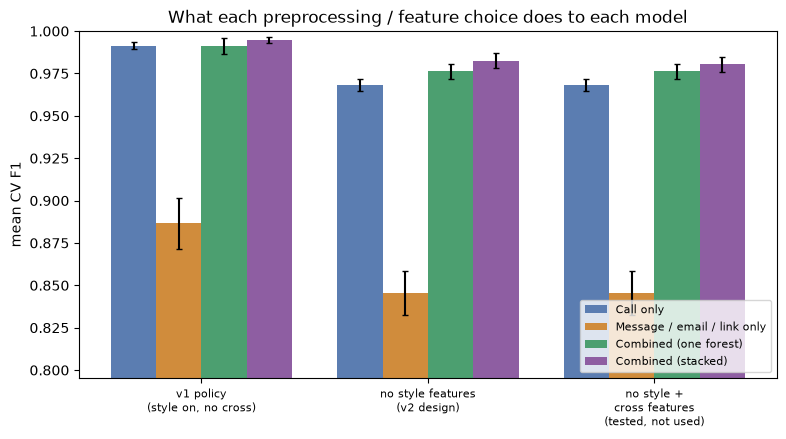

In [3]:
R.plot_ablation(d['ablation'], 'v2_01_ablation'); plt.show()

**How to read it:** if the call-only bar drops a lot when style features go, the old call score was partly dataset style. If the combined bars rise only when cross features are added, the gain really comes from seeing both channels.

## Who is right? (call model vs message model, out-of-fold)
`only_message_only_right` is the number of records where the message model is right and the call model wrong - the *only* room a combined model has to beat the call model.

both_right                 2657
only_call_only_right        506
only_message_only_right      85
both_wrong                   24
dtype: int64


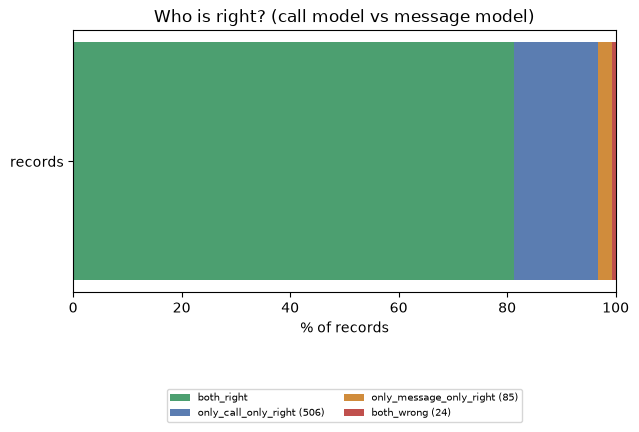

In [4]:
print(d['complementarity'])
R.plot_complementarity(d['complementarity'], 'v2_02_complementarity_dev'); plt.show()

## Spread over CV folds (policy 3)
Boxes that overlap mean the difference is inside the noise.

/home/rush/Downloads/Fase/ToadWatch_PR/toadwatch/reporting.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=folds, x="variant", y=metric, order=order, palette=[_color(v) for v in order], ax=ax, width=0.5)


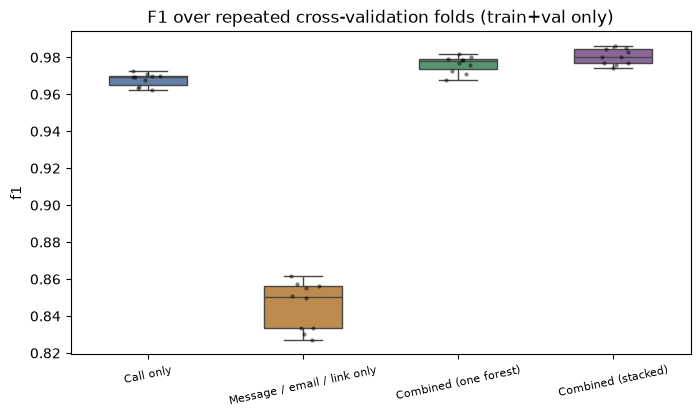

accuracy         precision          recall              f1         false_alarm_rate        
                     mean     std      mean     std    mean     std    mean     std             mean     std
variant                                                                                                     
call_only          0.9678  0.0036    0.9635  0.0105  0.9725  0.0090  0.9679  0.0035           0.0370  0.0113
combined_early     0.9762  0.0044    0.9728  0.0070  0.9798  0.0091  0.9762  0.0044           0.0275  0.0073
combined_stacked   0.9803  0.0043    0.9791  0.0088  0.9817  0.0061  0.9803  0.0042           0.0211  0.0091
message_only       0.8431  0.0135    0.8330  0.0230  0.8594  0.0246  0.8456  0.0130           0.1733  0.0299

In [5]:
folds, oof = d['folds_by_policy'][list(d['folds_by_policy'])[-1]]
R.plot_cv_scores(folds, 'f1'); plt.show()
folds.groupby('variant')[['accuracy','precision','recall','f1','false_alarm_rate']].agg(['mean','std']).round(4)